Следуя плану Perplexity. Неделя 1, знакомство

ДЕНЬ 1 : PyCharm + первые тензоры

In [1]:
pip show torch

Name: torch
Version: 2.12.0
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: https://pytorch.org
Author: 
Author-email: PyTorch Team <packages@pytorch.org>
License: BSD-3-Clause
Location: C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages
Requires: filelock, fsspec, jinja2, networkx, setuptools, sympy, typing-extensions
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch

# 1. Проверить версию
print(f"PyTorch версия: {torch.__version__}")

# 2. Создать тензор
x = torch.tensor([1.0, 2.0, 3.0])
print(f"Тензор: {x}")

# 3. Операции
y = x * 2
z = x + y
print(f"y = x*2: {y}")
print(f"z = x+y: {z}")

# 4. Сумма
total = x.sum()
print(f"Сумма: {total}")

PyTorch версия: 2.12.0+cpu
Тензор: tensor([1., 2., 3.])
y = x*2: tensor([2., 4., 6.])
z = x+y: tensor([3., 6., 9.])
Сумма: 6.0


In [3]:
# практика тензоров и операций с ними
import torch

# 1. Создать 10 разных тензоров
x1 = torch.zeros(3, 3)           # 3x3 нули
x2 = torch.ones(2, 4)            # 2x4 единицы
x3 = torch.randn(5, 5)           # 5x5 случайные (нормальное распределение)
x4 = torch.arange(0, 10)         # [0, 1, 2, ..., 9]
x5 = torch.linspace(0, 1, 5)     # [0.0, 0.25, 0.5, 0.75, 1.0]

# 2. Операции
a = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
b = torch.tensor([[5.0, 6.0], [7.0, 8.0]])

c = a + b                        # сложение
d = a * b                        # поэлементное умножение
e = torch.matmul(a, b)           # матричное умножение
f = a @ b                        # то же самое (@ оператор)

# 3. Сумма по осям
row_sum = b.sum(dim=0)           # сумма по колонкам
col_sum = b.sum(dim=1)           # сумма по строкам

print(f"Матричное произведение:\n{e}")
print(f"Сумма по колонкам: {row_sum}")
print(f"Сумма по строкам: {col_sum}")

Матричное произведение:
tensor([[19., 22.],
        [43., 50.]])
Сумма по колонкам: tensor([12., 14.])
Сумма по строкам: tensor([11., 15.])


ДЕНЬ 2 : autograd (автоматическое дифференцирование)
requires_grad=True → отслеживать градиенты

loss.backward() → вычислить градиенты

x.grad → доступ к градиентам

In [ ]:
# градиент
import torch

# 1. Тензор с requires_grad
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)

# 2. Функция
y = x**2 + torch.sin(x)

# 3. Loss
loss = y.sum()

# 4. Вычислить градиент
loss.backward()

# 5. Вывести градиент
print(f"Градиент dy/dx: {x.grad}")
# Ожидаемый вывод: [2+cos(1), 4+cos(2), 6+cos(3)] ≈ [2.54, 3.58, 4.99]

Градиент dy/dx: tensor([2.5403, 3.5839, 5.0100])


In [9]:
#Вторая производная
import torch

# 1. Тензор
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)

# 2. Функция
y = x**2 + torch.sin(x)

# 3. Первая производная
grad_outputs = torch.ones_like(y)
dy_dx = torch.autograd.grad(y, x, grad_outputs=grad_outputs, create_graph=True)[0]
print(f"Первая производная: {dy_dx}")

# 4. Вторая производная
d2y_dx2 = torch.autograd.grad(dy_dx, x, grad_outputs=torch.ones_like(dy_dx))[0]
print(f"Вторая производная: {d2y_dx2}")
# Ожидаемый вывод: [2-sin(1), 2-sin(2), 2-sin(3)] ≈ [1.16, 1.09, 0.86]

# 5. Очистить градиенты
x.grad = None

Первая производная: tensor([2.5403, 3.5839, 5.0100], grad_fn=<AddBackward0>)
Вторая производная: tensor([1.1585, 1.0907, 1.8589])


In [10]:
# Задача: вычислить градиент для f(x,y) = x²y + sin(xy)

x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(3.0, requires_grad=True)

f = x**2 * y + torch.sin(x * y)

# Градиенты
f.backward()

print(f"df/dx = {x.grad}")  # 2xy + y*cos(xy) = 12 + 3*cos(6) ≈ 11.04
print(f"df/dy = {y.grad}")  # x² + x*cos(xy) = 4 + 2*cos(6) ≈ 2.69

df/dx = 14.880510330200195
df/dy = 5.920340538024902


ДЕНЬ 3 : nn.Linear и nn.Sequential
Ключевые концепции:

nn.Linear(in_features, out_features) — линейный слой

nn.Sequential — последовательность слоев

nn.ReLU(), nn.Tanh() — функции активации

In [11]:
import torch.nn as nn

# 1. Создать линейный слой: 10 входов → 5 выходов
layer = nn.Linear(in_features=10, out_features=5)

# 2. Входные данные (batch size = 3)
x = torch.randn(3, 10)

# 3. Прямой проход
y = layer(x)

print(f"Вход: {x.shape}")   # (3, 10)
print(f"Выход: {y.shape}")  # (3, 5)

# 4. Параметры слоя
print(f"Веса: {layer.weight.shape}")    # (5, 10)
print(f"Смещение: {layer.bias.shape}")  # (5,)

Вход: torch.Size([3, 10])
Выход: torch.Size([3, 5])
Веса: torch.Size([5, 10])
Смещение: torch.Size([5])


In [13]:
# 1. Создать сеть: 1 → 64 → 32 → 16 → 1
model = nn.Sequential(
    nn.Linear(1, 64),
    nn.Tanh(),
    nn.Linear(64, 32),
    nn.Tanh(),
    nn.Linear(32, 16),
    nn.Tanh(),
    nn.Linear(16, 1)
)

# 2. Входные данные (100 примеров, 1 признак)
x = torch.randn(100, 1)

# 3. Предсказание
y_pred = model(x)

print(f"Вход: {x.shape}")    # (100, 1)
print(f"Выход: {y_pred.shape}")  # (100, 1)

# 4. Количество параметров
total_params = sum(p.numel() for p in model.parameters()) # numel() общее количество элементов в массиве параметров
print(f"Всего параметров: {total_params}")  # ≈ 2500

Вход: torch.Size([100, 1])
Выход: torch.Size([100, 1])
Всего параметров: 2753


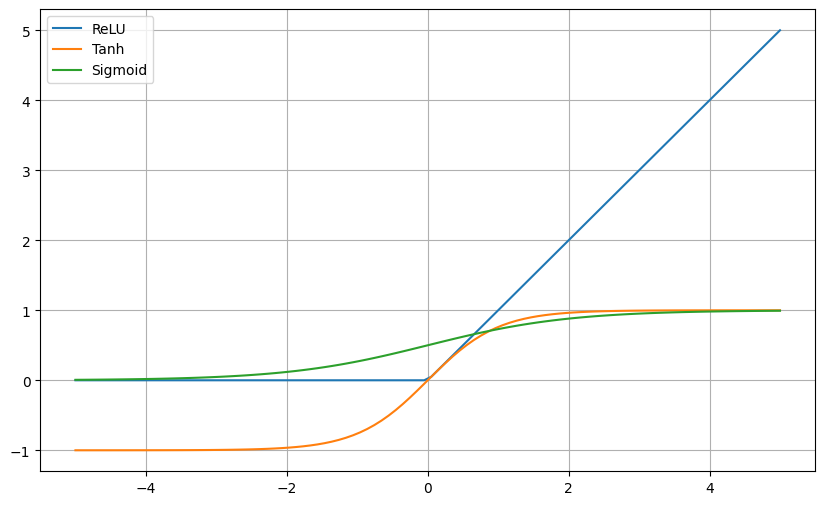

In [14]:
#Сравнение функций активации

import matplotlib.pyplot as plt

# 1. Входные данные
x = torch.linspace(-5, 5, 100)

# 2. Активации
relu = nn.ReLU()
tanh = nn.Tanh()
sigmoid = nn.Sigmoid()

y_relu = relu(x)
y_tanh = tanh(x)
y_sigmoid = sigmoid(x)

# 3. Визуализация
plt.figure(figsize=(10, 6))
plt.plot(x.numpy(), y_relu.numpy(), label='ReLU')
plt.plot(x.numpy(), y_tanh.numpy(), label='Tanh')
plt.plot(x.numpy(), y_sigmoid.numpy(), label='Sigmoid')
plt.legend()
plt.grid(True)
plt.savefig('activations.png')
plt.show()

ДЕНЬ 4 : Loss + Optimizer

In [15]:
# 1. Реальные и предсказанные значения
y_true = torch.tensor([[1.0], [2.0], [3.0], [4.0]])
y_pred = torch.tensor([[1.1], [1.9], [3.2], [3.8]])

# 2. MSE Loss
mse_loss = nn.MSELoss()
mse = mse_loss(y_pred, y_true)

# 3. L1 Loss (MAE)
l1_loss = nn.L1Loss()
mae = l1_loss(y_pred, y_true)

print(f"MSE: {mse.item()}")  # ≈ 0.015
print(f"MAE: {mae.item()}")  # ≈ 0.1

MSE: 0.025000009685754776
MAE: 0.15000003576278687


In [17]:
# Optimizer Adam
# 1. Модель
import torch.optim as optim

model = nn.Sequential(
    nn.Linear(1, 32),
    nn.Tanh(),
    nn.Linear(32, 1)
)

# 2. Optimizer
optimizer = optim.Adam(model.parameters(), lr=0.01)

# 3. Данные
x = torch.randn(100, 1)
y = 2 * x + 1 + 0.1 * torch.randn(100, 1)  # y = 2x + 1 + шум

# 4. Один шаг обучения
y_pred = model(x)
loss_fn = nn.MSELoss()
loss = loss_fn(y_pred, y)

# 5. Backprop
optimizer.zero_grad()  # очистить градиенты
loss.backward()        # вычислить градиенты
optimizer.step()       # обновить веса

print(f"Loss после 1 шага: {loss.item()}")

Loss после 1 шага: 6.065174102783203


In [18]:
# 10 шагов обучения
# 1. Модель
model = nn.Sequential(
    nn.Linear(1, 32),
    nn.Tanh(),
    nn.Linear(32, 1)
)

# 2. Optimizer + Loss
optimizer = optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.MSELoss()

# 3. Данные
x = torch.randn(100, 1)
y = 2 * x + 1 + 0.1 * torch.randn(100, 1)

# 4. 10 шагов обучения
for step in range(10):
    y_pred = model(x)
    loss = loss_fn(y_pred, y)
    
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    print(f"Step {step}, Loss: {loss.item():.4f}")

Step 0, Loss: 2.4676
Step 1, Loss: 2.1196
Step 2, Loss: 1.8046
Step 3, Loss: 1.5215
Step 4, Loss: 1.2688
Step 5, Loss: 1.0442
Step 6, Loss: 0.8458
Step 7, Loss: 0.6725
Step 8, Loss: 0.5234
Step 9, Loss: 0.3982


ДЕНЬ 5: Train loop полный

Epoch 0, Loss: 0.5321
Epoch 50, Loss: 0.4254
Epoch 100, Loss: 0.2062
Epoch 150, Loss: 0.1236
Epoch 200, Loss: 0.0871
Epoch 250, Loss: 0.0702
Epoch 300, Loss: 0.0627
Epoch 350, Loss: 0.0427
Epoch 400, Loss: 0.0253
Epoch 450, Loss: 0.0215


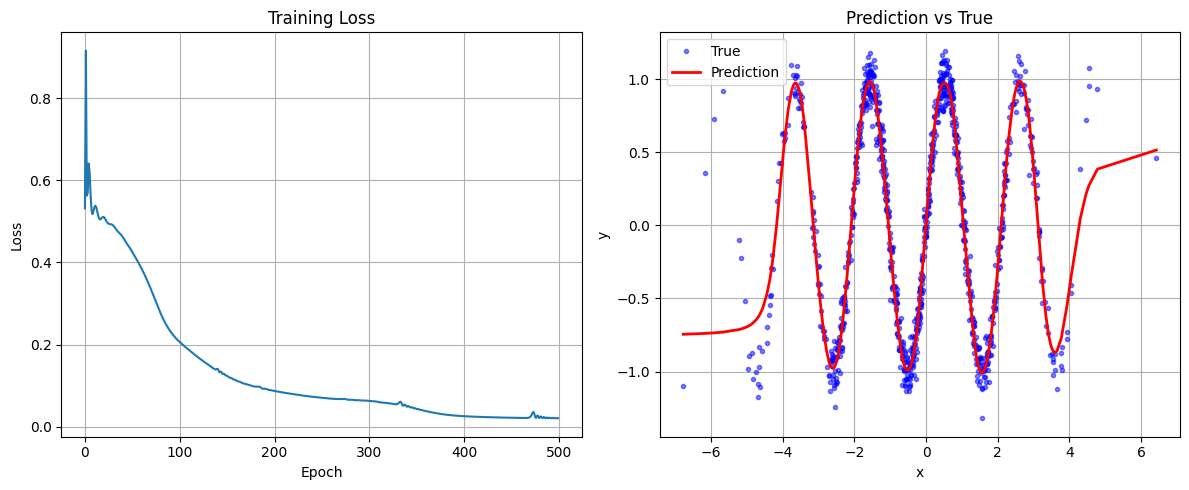

In [20]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# 1. Модель
model = nn.Sequential(
    nn.Linear(1, 64),
    nn.Tanh(),
    nn.Linear(64, 32),
    nn.Tanh(),
    nn.Linear(32, 1)
)

# 2. Optimizer + Loss
optimizer = optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.MSELoss()

# 3. Данные (синусоида)
x = torch.randn(1000, 1) * 2
y = torch.sin(x * 3) + 0.1 * torch.randn(1000, 1)

# 4. Train loop
losses = []
for epoch in range(500):
    y_pred = model(x)
    loss = loss_fn(y_pred, y)
    
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    losses.append(loss.item())
    
    if epoch % 50 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

# 5. Визуализация
plt.figure(figsize=(12, 5))

# Loss curve
plt.subplot(1, 2, 1)
plt.plot(losses)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.grid(True)

# Prediction vs True
plt.subplot(1, 2, 2)
x_sorted, y_sorted = zip(*sorted(zip(x.numpy().flatten(), y.numpy().flatten())))
x_sorted = torch.tensor(x_sorted).unsqueeze(1)
y_sorted = torch.tensor(y_sorted).unsqueeze(1)

with torch.no_grad():
    y_pred_sorted = model(x_sorted)

plt.plot(x_sorted.numpy(), y_sorted.numpy(), 'b.', label='True', alpha=0.5)
plt.plot(x_sorted.numpy(), y_pred_sorted.numpy(), 'r-', label='Prediction', linewidth=2)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Prediction vs True')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('train_result.png')
plt.show()

ДЕНЬ 6 : DataLoader

In [30]:
# Создаем
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# 1. Данные
x = torch.randn(1000, 1)
y = torch.sin(x * 3) + 0.1 * torch.randn(1000, 1)

# 2. Dataset
dataset = TensorDataset(x, y)

# 3. DataLoader (batch size=32, shuffle=True)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

# 4. Модель
model = nn.Sequential(
    nn.Linear(1, 64),
    nn.Tanh(),
    nn.Linear(64, 1)
)

optimizer = optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.MSELoss()

# 5. Train с DataLoader
for epoch in range(10):
    epoch_loss = 0
    for batch_x, batch_y in dataloader:
        y_pred = model(batch_x)
        loss = loss_fn(y_pred, batch_y)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
    
    print(f"Epoch {epoch}, Loss: {epoch_loss / len(dataloader):.4f}")

Epoch 0, Loss: 0.5417
Epoch 1, Loss: 0.4595
Epoch 2, Loss: 0.3387
Epoch 3, Loss: 0.2626
Epoch 4, Loss: 0.1804
Epoch 5, Loss: 0.1549
Epoch 6, Loss: 0.1348
Epoch 7, Loss: 0.1141
Epoch 8, Loss: 0.1057
Epoch 9, Loss: 0.0957
